# CVM-A1: phân tích thời gian và bộ nhớ

Notebook này có ba chế độ: `READ_EXISTING_P0` đọc kết quả P0 đã lưu trên Windows; `SMOKE_LINUX` chạy một smoke test thật qua API TV3; `CUSTOM_SWEEP` chạy cấu hình tùy chỉnh qua API TV3. Chế độ mặc định chỉ đọc dữ liệu có sẵn.

Thời gian thuật toán, thời gian đầu-cuối, RSS của tiến trình C++ và kích thước mẫu là các đại lượng khác nhau. Số liệu P0 chỉ mô tả máy Windows ghi trong sidecar; không dùng chúng làm phép đo Linux. Một điểm `m` không đủ để suy luận xu hướng tiệm cận Big-O.


In [1]:
from pathlib import Path
import importlib.util
import json
import math
import platform
import shutil
import subprocess
import sys

from IPython.display import Image, Markdown, display
import pandas as pd

def find_project_root(start: Path = Path.cwd()) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file() and (candidate / "src").is_dir():
            return candidate
    raise FileNotFoundError("Không tìm thấy thư mục gốc có pyproject.toml và src/.")

ROOT = find_project_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

EXPORT_DIR = ROOT / "notebooks" / "exports"
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
P0_RAW = ROOT / "results" / "real" / "tv4_timespace_p0_20261113.csv"
P0_SIDECAR = P0_RAW.with_suffix(".metadata.json")
P0_SUMMARY = ROOT / "results" / "summary" / "timespace_summary.csv"
P0_FIGURES = ROOT / "results" / "summary" / "figures"

compiler_path = shutil.which("g++") or shutil.which("clang++")
compiler_version = "không tìm thấy GCC/Clang"
if compiler_path:
    result = subprocess.run([compiler_path, "--version"], capture_output=True, text=True, check=False)
    compiler_version = (result.stdout or result.stderr).splitlines()[0]

display(Markdown("\n".join([
    f"**Kernel:** `{sys.executable}`",
    f"**Python:** `{platform.python_version()}`",
    f"**Hệ điều hành hiện tại:** `{platform.platform()}`",
    f"**Trình biên dịch:** `{compiler_version}`",
])))


**Kernel:** `/tmp/cvm-tv2-jupyter-venv/bin/python`
**Python:** `3.14.4`
**Hệ điều hành hiện tại:** `Linux-7.0.0-43-generic-x86_64-with-glibc2.43`
**Trình biên dịch:** `g++ (Ubuntu 15.2.0-16ubuntu1) 15.2.0`

## Cấu hình chế độ chạy

Chọn `READ_EXISTING_P0` để Run All chỉ đọc dữ liệu đã lưu. `SMOKE_LINUX` chạy hai lượt smoke qua API TV3. `CUSTOM_SWEEP` mặc định chỉ kiểm tra cấu hình; đặt `RUN_CUSTOM = True` để cho phép chạy benchmark.


In [2]:
MODE = "READ_EXISTING_P0"  # READ_EXISTING_P0 | SMOKE_LINUX | CUSTOM_SWEEP
RUN_CUSTOM = False

# Tham số dùng cho CUSTOM_SWEEP. n và f0 là giá trị đơn; để None để TV3 suy ra.
CUSTOM_M = [256, 1024]
CUSTOM_N = None
CUSTOM_F0 = None
CUSTOM_EPSILON = 0.05
CUSTOM_DELTA = 0.01
CUSTOM_WORKLOADS = ["uniform"]
CUSTOM_SEED_GENERATOR = 44000
CUSTOM_SEED_ALGORITHM = 84000
CUSTOM_TRIALS = 2

ALLOWED_MODES = {"READ_EXISTING_P0", "SMOKE_LINUX", "CUSTOM_SWEEP"}
if MODE not in ALLOWED_MODES:
    raise ValueError(f"MODE phải thuộc {sorted(ALLOWED_MODES)}, nhận được {MODE!r}.")

def validate_custom_config() -> None:
    if not CUSTOM_M or any(isinstance(m, bool) or not isinstance(m, int) or m < 1 for m in CUSTOM_M):
        raise ValueError("CUSTOM_M phải là danh sách số nguyên dương, không rỗng.")
    if not CUSTOM_WORKLOADS:
        raise ValueError("CUSTOM_WORKLOADS không được rỗng.")
    if any(w not in {"all_duplicate", "all_distinct", "uniform", "skewed", "zipf"} for w in CUSTOM_WORKLOADS):
        raise ValueError("CUSTOM_WORKLOADS chứa workload không được hỗ trợ.")
    for name, value in (("epsilon", CUSTOM_EPSILON), ("delta", CUSTOM_DELTA)):
        if not math.isfinite(value) or not 0.0 < value < 1.0:
            raise ValueError(f"{name} phải hữu hạn và thuộc (0, 1).")
    if isinstance(CUSTOM_TRIALS, bool) or not isinstance(CUSTOM_TRIALS, int) or CUSTOM_TRIALS < 1:
        raise ValueError("CUSTOM_TRIALS phải là số nguyên dương.")
    for name, seed in (("seed_generator", CUSTOM_SEED_GENERATOR), ("seed_algorithm", CUSTOM_SEED_ALGORITHM)):
        if isinstance(seed, bool) or not isinstance(seed, int) or seed < 0 or seed >= 2**64:
            raise ValueError(f"{name} phải thuộc miền uint64.")
    if CUSTOM_N is not None and (isinstance(CUSTOM_N, bool) or not isinstance(CUSTOM_N, int) or not 1 <= CUSTOM_N <= 2**64):
        raise ValueError("CUSTOM_N phải thuộc [1, 2**64] hoặc là None.")
    if CUSTOM_F0 is not None and (isinstance(CUSTOM_F0, bool) or not isinstance(CUSTOM_F0, int) or not 1 <= CUSTOM_F0 < 2**64):
        raise ValueError("CUSTOM_F0 phải thuộc [1, 2**64) hoặc là None.")
    for m in CUSTOM_M:
        for workload in CUSTOM_WORKLOADS:
            if CUSTOM_F0 is not None and CUSTOM_F0 > m:
                raise ValueError(f"F0={CUSTOM_F0} vượt m={m}.")
            if CUSTOM_N is not None and CUSTOM_F0 is not None and CUSTOM_F0 > CUSTOM_N:
                raise ValueError(f"F0={CUSTOM_F0} vượt n={CUSTOM_N}.")
            if workload == "all_distinct":
                if CUSTOM_N is not None and CUSTOM_N < m:
                    raise ValueError(f"all_distinct yêu cầu n >= m (m={m}, n={CUSTOM_N}).")
                if CUSTOM_F0 is not None and CUSTOM_F0 != m:
                    raise ValueError(f"all_distinct yêu cầu F0=m (m={m}, F0={CUSTOM_F0}).")
            if workload == "all_duplicate" and CUSTOM_F0 not in (None, 1):
                raise ValueError("all_duplicate yêu cầu F0=1.")

validate_custom_config()


## Chạy chế độ đã chọn

Notebook xác thực P0 bằng validator hiện có. Khi API TV4 có mặt, notebook gọi API đó để tạo bảng và hình. Trước khi API TV4 được ghép, chế độ P0 đọc bảng tổng hợp và PNG đã lưu, đồng thời báo rõ trạng thái tích hợp.


**Nguồn:** Windows P0 đã lưu
**Xác thực:** `verified_real`
**Số bản ghi:** 135
**Phép đo Linux:** chưa thực hiện

**CHỜ API TV4:** đang hiển thị bảng và hình P0 đã lưu; chưa chạy phân tích trong notebook.

,run_id,algorithm,workload,trial,m,n,F0,epsilon,delta,s,...,algorithm_runtime_ms,end_to_end_runtime_ms,peak_sample_size,halving_count,process_peak_memory_bytes,signed_rel_error,abs_rel_error,env_os,compiler,build_flags
0,41750a56-3def-49f2-a6ff-8f2e64e3f481,CVM-A1,all_distinct,1,16384,65536,16384,0.5,0.05,1024,...,1.2121,44.1944,1024,5,4898816,-0.027344,0.027344,Windows-11,"g++.EXE (MinGW-W64 x86_64-msvcrt-posix-seh, bu...",-O3;-std=c++17;-Isrc
1,9634d469-daeb-4963-8420-b80113f2fd12,CVM-A1,all_distinct,2,16384,65536,16384,0.5,0.05,1024,...,1.1638,45.1711,1024,5,4894720,-0.031250,0.031250,Windows-11,"g++.EXE (MinGW-W64 x86_64-msvcrt-posix-seh, bu...",-O3;-std=c++17;-Isrc
2,94b7f735-37f8-4128-b7ac-1c2d1db4f20d,CVM-A1,all_distinct,3,16384,65536,16384,0.5,0.05,1024,...,1.1519,48.5745,1024,4,4911104,-0.026367,0.026367,Windows-11,"g++.EXE (MinGW-W64 x86_64-msvcrt-posix-seh, bu...",-O3;-std=c++17;-Isrc
3,acc7e8bb-714c-44f9-b731-23a033c567ac,CVM-A1,all_distinct,4,16384,65536,16384,0.5,0.05,1024,...,1.2135,41.6582,1024,4,4894720,-0.016602,0.016602,Windows-11,"g++.EXE (MinGW-W64 x86_64-msvcrt-posix-seh, bu...",-O3;-std=c++17;-Isrc
4,de049ffa-2e66-4293-8aed-3a838df25ade,CVM-A1,all_distinct,5,16384,65536,16384,0.5,0.05,1024,...,1.1509,44.0596,1024,4,4907008,-0.035156,0.035156,Windows-11,"g++.EXE (MinGW-W64 x86_64-msvcrt-posix-seh, bu...",-O3;-std=c++17;-Isrc
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
130,943a4640-43c1-4cf2-a7a4-abecc12383c2,CVM-A1,uniform,5,4096,65536,1024,0.5,0.05,928,...,0.4714,30.4752,928,1,4902912,0.025391,0.025391,Windows-11,"g++.EXE (MinGW-W64 x86_64-msvcrt-posix-seh, bu...",-O3;-std=c++17;-Isrc
131,a5e897b1-33cd-41de-b667-6ac4cff7f103,CVM-A1,uniform,6,4096,65536,1024,0.5,0.05,928,...,0.4713,27.7789,928,1,4890624,-0.023438,0.023438,Windows-11,"g++.EXE (MinGW-W64 x86_64-msvcrt-posix-seh, bu...",-O3;-std=c++17;-Isrc
132,0f2e5508-2344-409b-a89a-2eeb9821220a,CVM-A1,uniform,7,4096,65536,1024,0.5,0.05,928,...,0.4383,28.9895,928,1,4894720,-0.027344,0.027344,Windows-11,"g++.EXE (MinGW-W64 x86_64-msvcrt-posix-seh, bu...",-O3;-std=c++17;-Isrc
133,ae693ec8-3c69-4726-bdd2-c6100edd5b39,CVM-A1,uniform,8,4096,65536,1024,0.5,0.05,928,...,0.4853,30.5563,928,1,4894720,-0.023438,0.023438,Windows-11,"g++.EXE (MinGW-W64 x86_64-msvcrt-posix-seh, bu...",-O3;-std=c++17;-Isrc


,algorithm,workload,m,n,F0,epsilon,delta,s,env_os,platform_os,...,signed_rel_error_median,abs_rel_error_count,abs_rel_error_mean,abs_rel_error_median,abort_runtime_count,abort_runtime_mean,abort_runtime_median,abort_runtime_min,abort_runtime_max,abort_runtime_stdev
0,CVM-A1,all_distinct,256,65536,256,0.5,0.05,736,Windows-11,Windows-11-10.0.26200-SP0,...,0.000000,9,0.000000,0.000000,0,NaN,NaN,NaN,NaN,NaN
1,CVM-A1,all_distinct,1024,65536,1024,0.5,0.05,832,Windows-11,Windows-11-10.0.26200-SP0,...,0.021484,9,0.028212,0.025391,0,NaN,NaN,NaN,NaN,NaN
2,CVM-A1,all_distinct,4096,65536,4096,0.5,0.05,928,Windows-11,Windows-11-10.0.26200-SP0,...,0.003906,9,0.025174,0.023438,0,NaN,NaN,NaN,NaN,NaN
3,CVM-A1,all_distinct,16384,65536,16384,0.5,0.05,1024,Windows-11,Windows-11-10.0.26200-SP0,...,-0.027344,9,0.032227,0.031250,0,NaN,NaN,NaN,NaN,NaN
4,CVM-A1,all_distinct,65536,65536,65536,0.5,0.05,1120,Windows-11,Windows-11-10.0.26200-SP0,...,-0.012695,9,0.020833,0.017578,0,NaN,NaN,NaN,NaN,NaN
5,CVM-A1,all_duplicate,256,65536,1,0.5,0.05,736,Windows-11,Windows-11-10.0.26200-SP0,...,0.000000,9,0.000000,0.000000,0,NaN,NaN,NaN,NaN,NaN
6,CVM-A1,all_duplicate,1024,65536,1,0.5,0.05,832,Windows-11,Windows-11-10.0.26200-SP0,...,0.000000,9,0.000000,0.000000,0,NaN,NaN,NaN,NaN,NaN
7,CVM-A1,all_duplicate,4096,65536,1,0.5,0.05,928,Windows-11,Windows-11-10.0.26200-SP0,...,0.000000,9,0.000000,0.000000,0,NaN,NaN,NaN,NaN,NaN
8,CVM-A1,all_duplicate,16384,65536,1,0.5,0.05,1024,Windows-11,Windows-11-10.0.26200-SP0,...,0.000000,9,0.000000,0.000000,0,NaN,NaN,NaN,NaN,NaN
9,CVM-A1,all_duplicate,65536,65536,1,0.5,0.05,1120,Windows-11,Windows-11-10.0.26200-SP0,...,0.000000,9,0.000000,0.000000,0,NaN,NaN,NaN,NaN,NaN


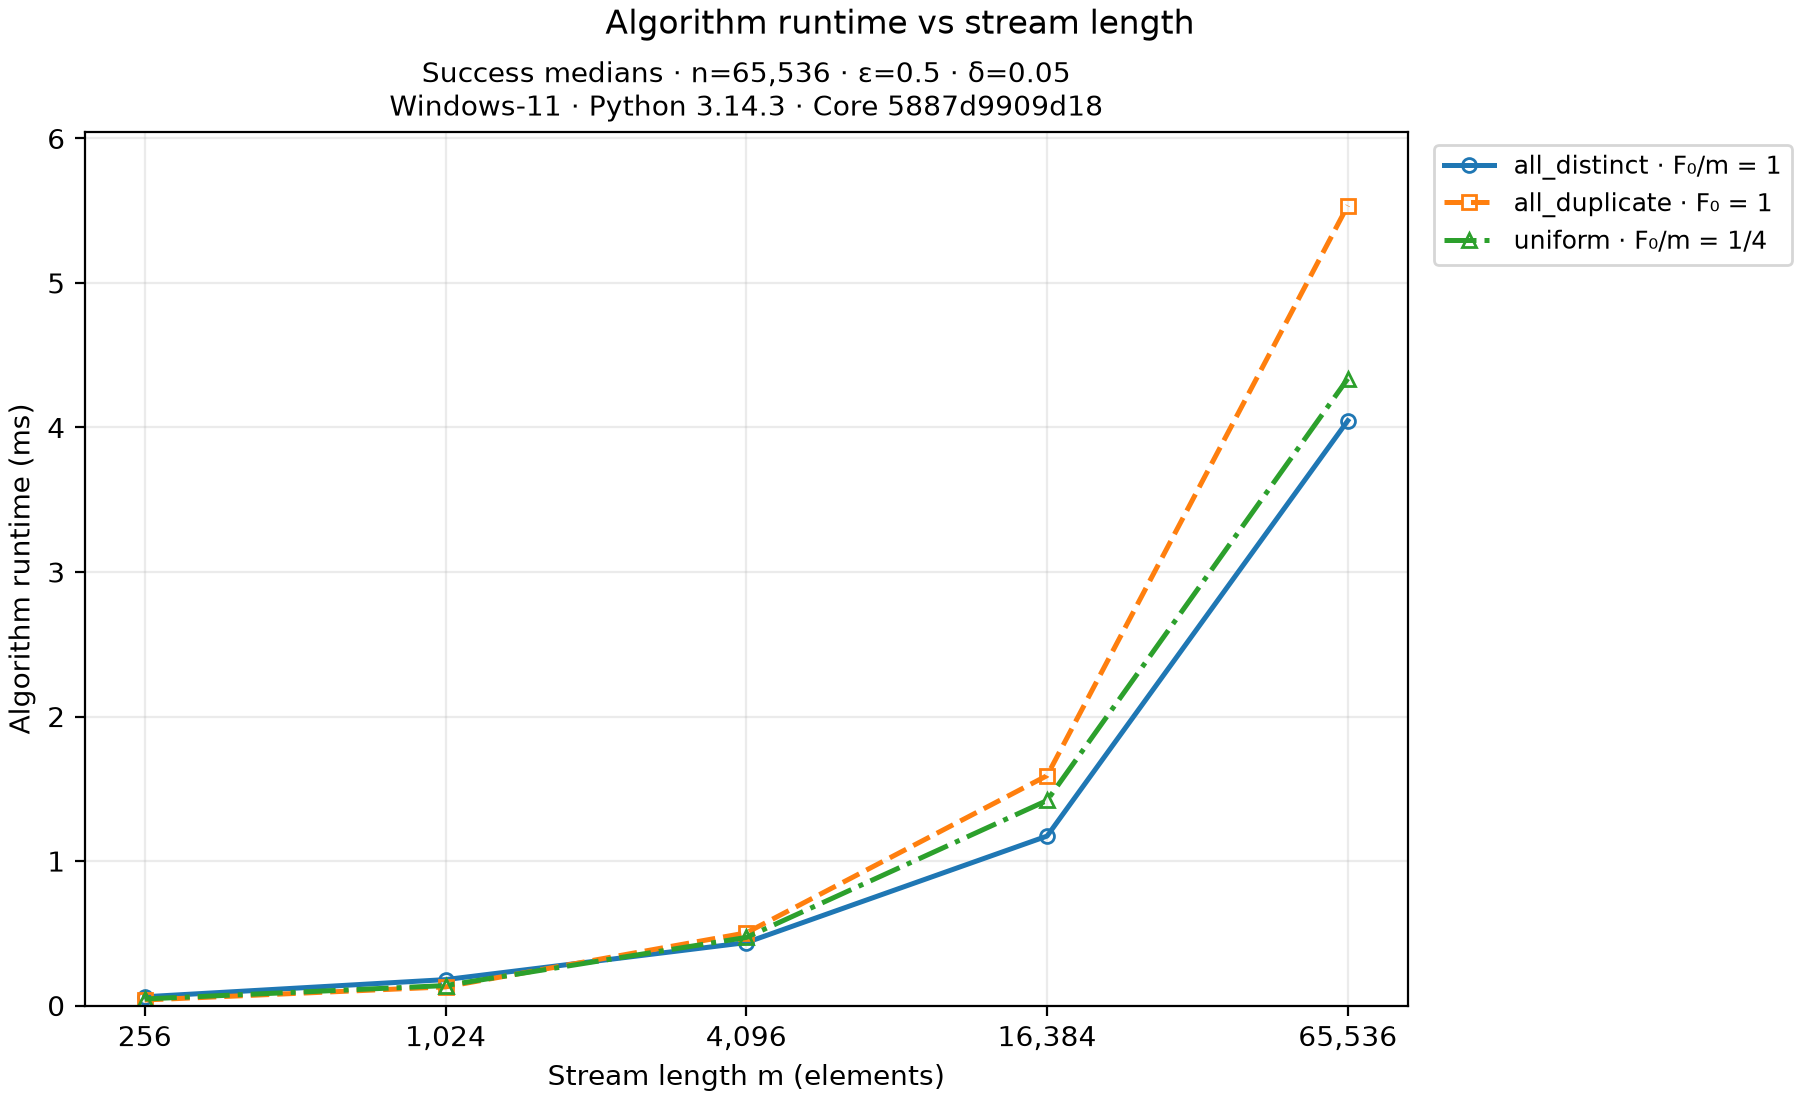

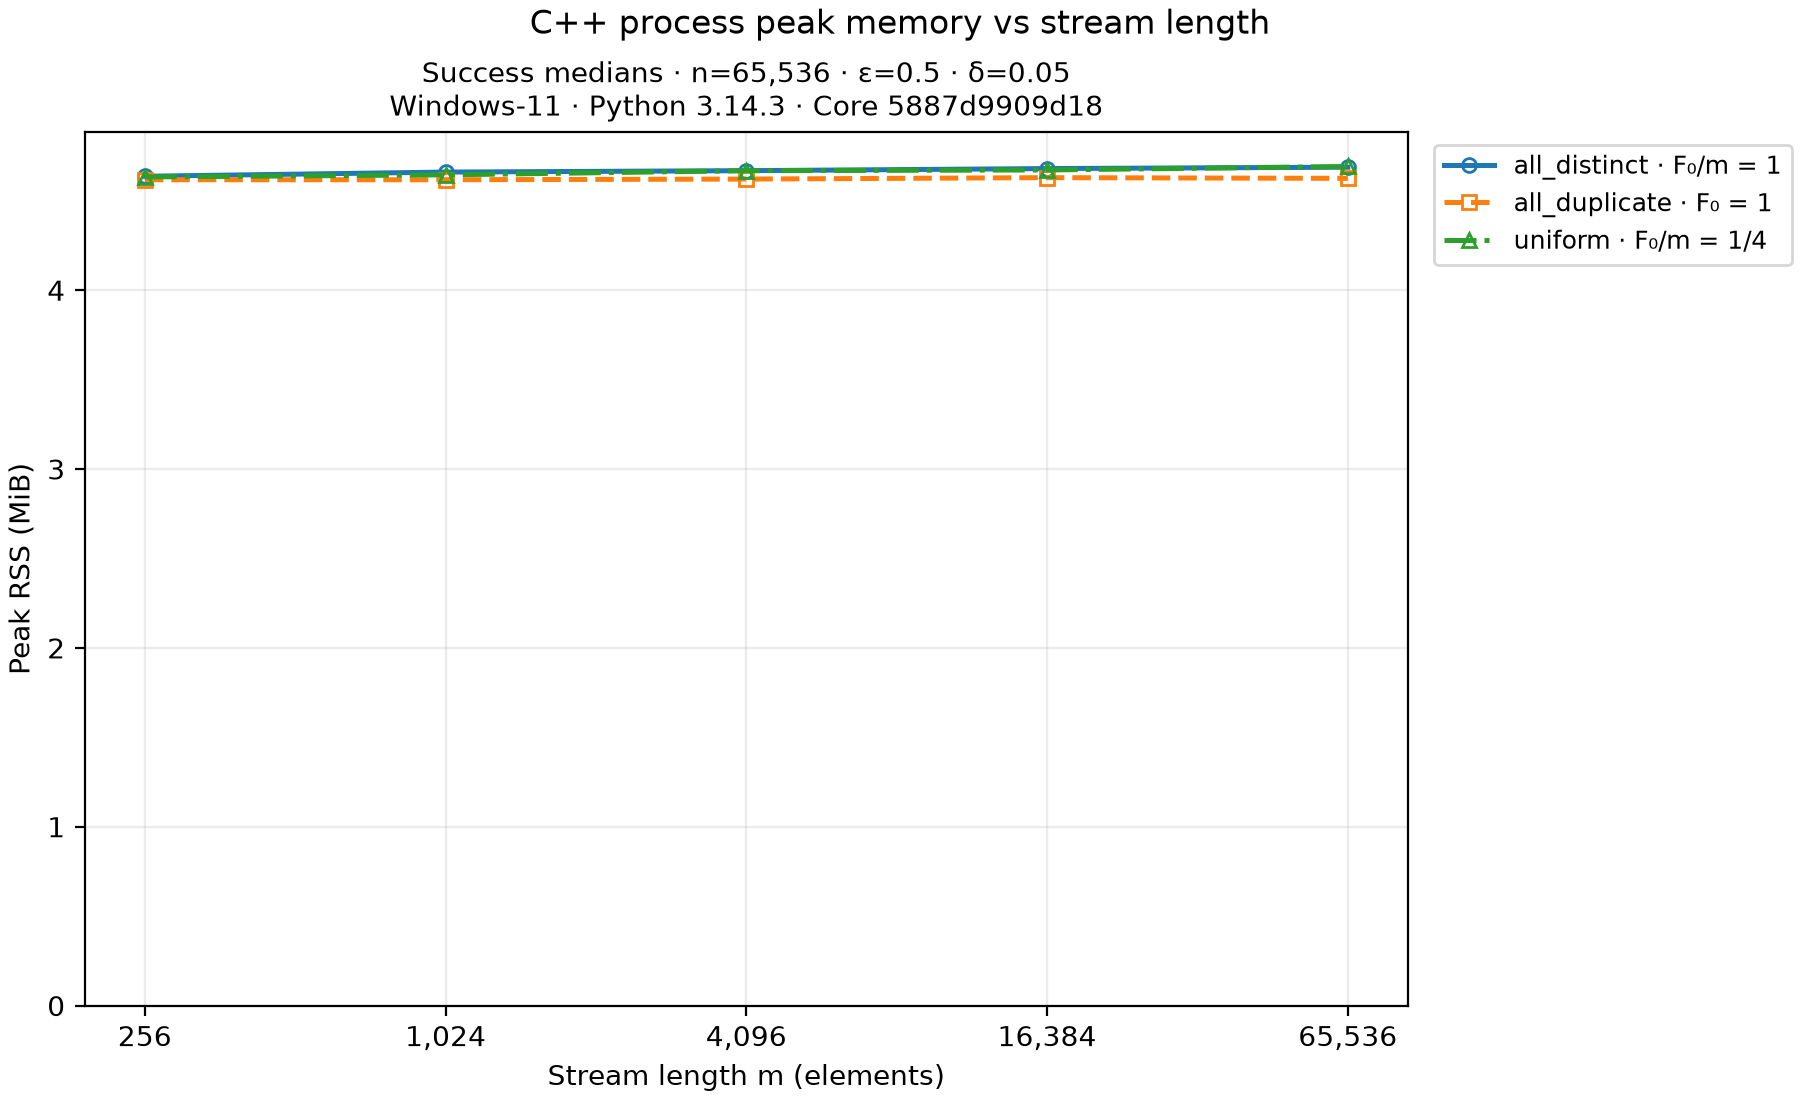

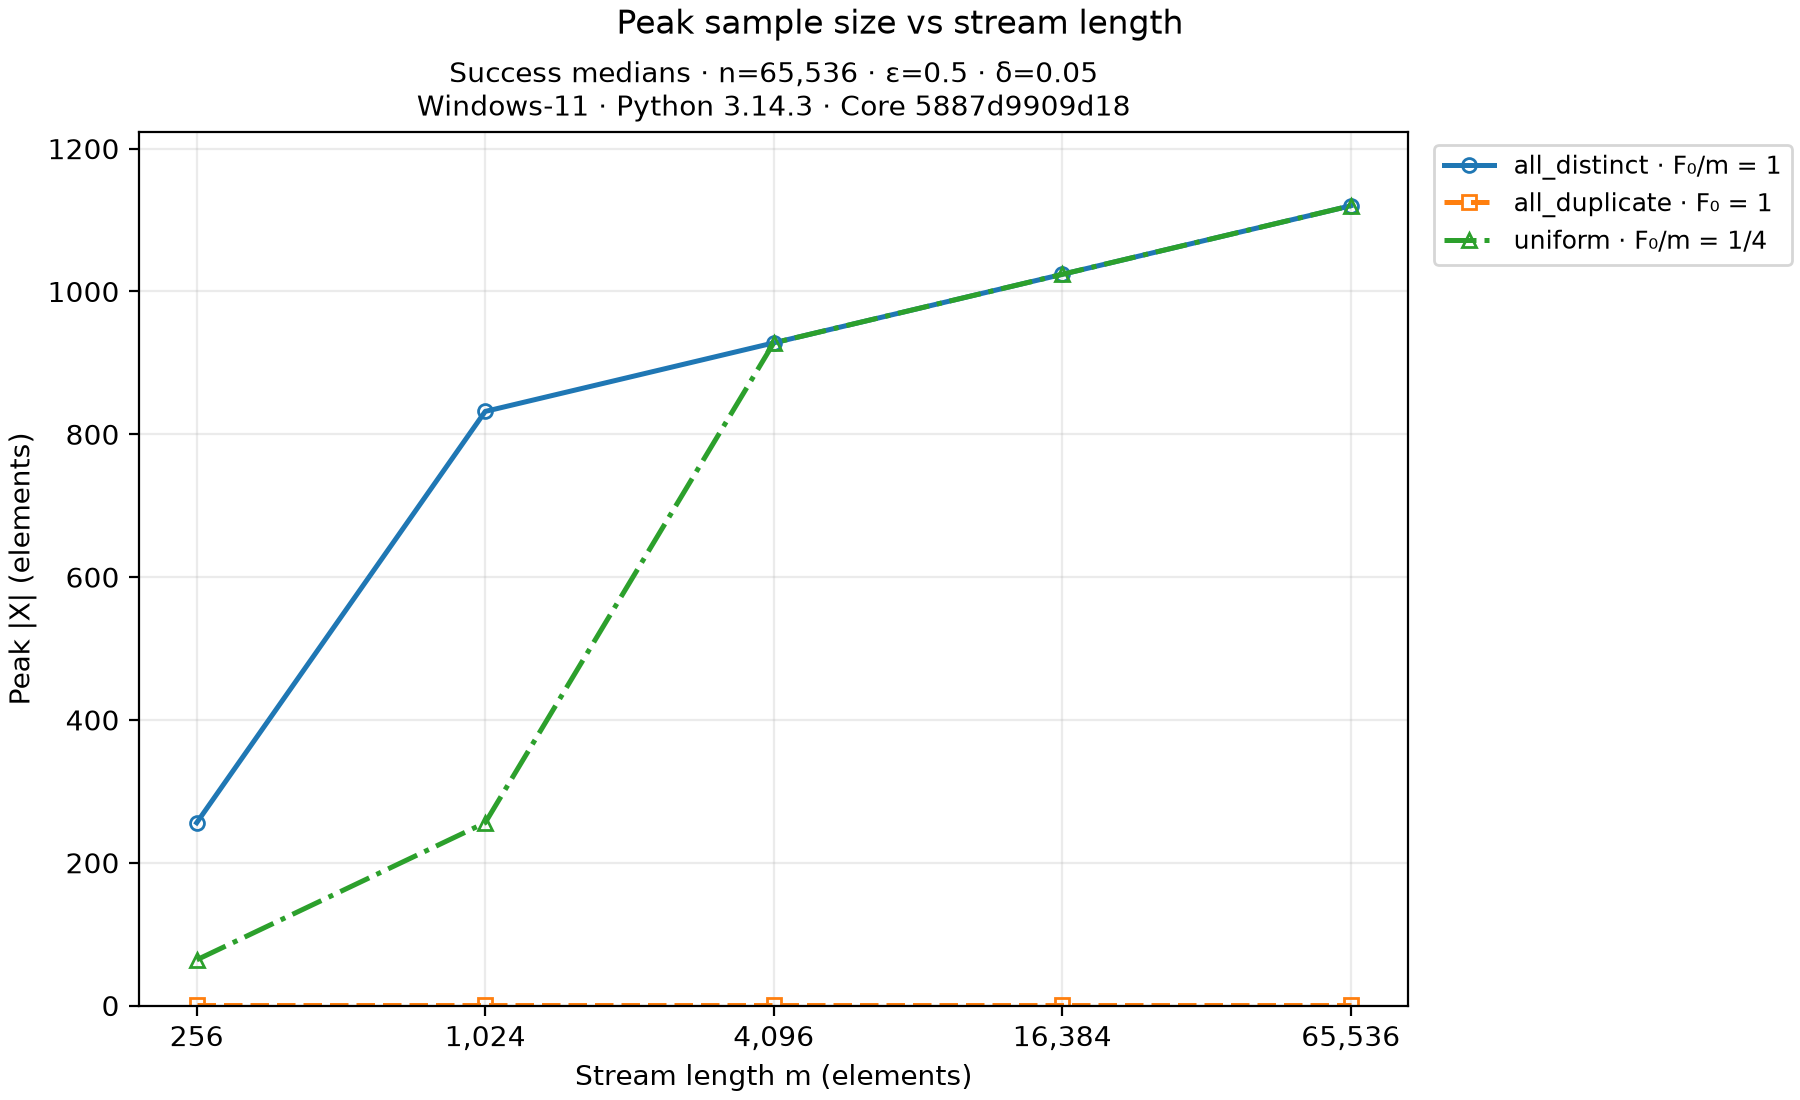

Thư mục xuất: /home/tuan-anh/Documents/distinct-elements-cvm-analysis-tv2/notebooks/exports


In [3]:
def copy_artifact(source: Path, target_name: str | None = None) -> Path:
    destination = EXPORT_DIR / (target_name or source.name)
    shutil.copy2(source, destination)
    return destination

def show_analysis(report) -> None:
    display(Markdown("\n".join([
        f"**RAW:** `{report.provenance.raw_path}`",
        f"**Sidecar:** `{report.provenance.metadata_path}`",
        f"**Phân loại:** `{report.provenance.classification}`",
    ])))
    display(report.raw)
    display(report.summary)
    for image_path in report.png_paths:
        display(Image(filename=str(image_path), width=900))
    display(Markdown("\n".join(f"- {note}" for note in report.notes)))
    copy_artifact(report.provenance.raw_path)
    copy_artifact(report.provenance.metadata_path)
    copy_artifact(report.summary_path)
    for image_path in report.png_paths:
        copy_artifact(image_path)

analysis_api_available = importlib.util.find_spec("scripts.jupyter_analysis") is not None
benchmark_api_available = importlib.util.find_spec("src.jupyter_adapter") is not None
analysis_report = None
benchmark_result = None

if MODE == "READ_EXISTING_P0":
    from scripts.validate_results import validate

    if not P0_RAW.is_file() or not P0_SIDECAR.is_file():
        raise FileNotFoundError(f"Thiếu RAW hoặc sidecar P0: {P0_RAW}")
    validation = validate(P0_RAW, P0_SIDECAR)
    if not validation.verified:
        raise ValueError("P0 không qua xác thực:\n" + "\n".join(validation.errors))
    raw_frame = pd.read_csv(P0_RAW)
    display(Markdown("\n".join([
        "**Nguồn:** Windows P0 đã lưu",
        f"**Xác thực:** `{validation.classification}`",
        f"**Số bản ghi:** {len(raw_frame)}",
        "**Phép đo Linux:** chưa thực hiện",
    ])))
    if analysis_api_available:
        from scripts.jupyter_analysis import analyze_jupyter_results

        analysis_report = analyze_jupyter_results(P0_RAW, EXPORT_DIR / "tv4", metadata_path=P0_SIDECAR)
        show_analysis(analysis_report)
        print(f"Bảng tổng hợp đã xuất: {analysis_report.summary_path}")
        print(f"Báo cáo TV4: {analysis_report.markdown_path}")
    else:
        if not P0_SUMMARY.is_file():
            raise FileNotFoundError(f"Thiếu bảng tổng hợp P0: {P0_SUMMARY}")
        summary_frame = pd.read_csv(P0_SUMMARY)
        display(Markdown("**CHỜ API TV4:** đang hiển thị bảng và hình P0 đã lưu; chưa chạy phân tích trong notebook."))
        display(raw_frame)
        display(summary_frame)
        for metric in ("runtime", "ram", "sample"):
            image_path = P0_FIGURES / f"timespace_{metric}.png"
            if not image_path.is_file():
                raise FileNotFoundError(f"Thiếu hình P0: {image_path}")
            display(Image(filename=str(image_path), width=900))
            copy_artifact(image_path)
        copy_artifact(P0_RAW)
        copy_artifact(P0_SIDECAR)
        copy_artifact(P0_SUMMARY)
    if len(raw_frame) != 135:
        raise ValueError(f"P0 dự kiến có 135 bản ghi, nhận được {len(raw_frame)}.")
    if len(pd.read_csv(P0_SUMMARY)) != 15:
        raise ValueError("Bảng tổng hợp P0 dự kiến có 15 nhóm.")

elif MODE == "SMOKE_LINUX":
    if not benchmark_api_available:
        display(Markdown("**CHỜ API TV3:** `src.jupyter_adapter` chưa có trong checkout này. Không tạo RAW và không giả lập kết quả."))
    else:
        from src.jupyter_adapter import run_jupyter_benchmark

        benchmark_result = run_jupyter_benchmark(preset="smoke", output_dir=EXPORT_DIR / "real")
        display(Markdown("\n".join([
                "**Status:** smoke đã chạy qua API TV3",
                f"**RAW:** `{benchmark_result.csv_path}`",
                f"**Sidecar:** `{benchmark_result.sidecar_path}`",
                f"**Bản ghi:** {benchmark_result.records_count} · **Cấu hình:** {benchmark_result.configs_count}",
            ])))
        display(benchmark_result.to_dataframe)
        if analysis_api_available:
            from scripts.jupyter_analysis import analyze_jupyter_results

            analysis_report = analyze_jupyter_results(
                benchmark_result.csv_path, EXPORT_DIR / "tv4", metadata_path=benchmark_result.sidecar_path
            )
            show_analysis(analysis_report)
        else:
            display(Markdown("**CHỜ API TV4:** RAW đã được TV3 tạo; bảng phân tích và hình sẽ xuất hiện sau khi ghép API TV4."))

else:  # CUSTOM_SWEEP
    if not RUN_CUSTOM:
        display(Markdown(
            f"**Chưa chạy benchmark.** Kế hoạch gồm {len(CUSTOM_M) * len(CUSTOM_WORKLOADS)} cấu hình × "
            f"{CUSTOM_TRIALS} trial = {len(CUSTOM_M) * len(CUSTOM_WORKLOADS) * CUSTOM_TRIALS} lượt. "
            "Đặt `RUN_CUSTOM = True` để chạy."
        ))
    elif not benchmark_api_available:
        display(Markdown("**CHỜ API TV3:** `src.jupyter_adapter` chưa có trong checkout này. Không tạo RAW và không giả lập kết quả."))
    else:
        from src.jupyter_adapter import run_jupyter_benchmark

        benchmark_result = run_jupyter_benchmark(
            m=CUSTOM_M,
            n=CUSTOM_N,
            f0=CUSTOM_F0,
            epsilon=CUSTOM_EPSILON,
            delta=CUSTOM_DELTA,
            workload=CUSTOM_WORKLOADS,
            trials=CUSTOM_TRIALS,
            seed_generator=CUSTOM_SEED_GENERATOR,
            seed_algorithm=CUSTOM_SEED_ALGORITHM,
            output_dir=EXPORT_DIR / "real",
            tag="custom_sweep",
        )
        display(Markdown("\n".join([
                "**Status:** custom sweep đã chạy qua API TV3",
                f"**RAW:** `{benchmark_result.csv_path}`",
                f"**Sidecar:** `{benchmark_result.sidecar_path}`",
                f"**Bản ghi:** {benchmark_result.records_count} · **Cấu hình:** {benchmark_result.configs_count}",
            ])))
        display(benchmark_result.to_dataframe)
        if analysis_api_available:
            from scripts.jupyter_analysis import analyze_jupyter_results

            analysis_report = analyze_jupyter_results(
                benchmark_result.csv_path, EXPORT_DIR / "tv4", metadata_path=benchmark_result.sidecar_path
            )
            show_analysis(analysis_report)
        else:
            display(Markdown("**CHỜ API TV4:** RAW đã được TV3 tạo; bảng phân tích và hình sẽ xuất hiện sau khi ghép API TV4."))

print(f"Thư mục xuất: {EXPORT_DIR}")


## Diễn giải và giới hạn

P0 gồm các phép đo trên Windows và dùng để đối chiếu cách đọc, xác thực, tổng hợp và hiển thị. Kết quả smoke/custom chỉ được gọi là phép đo Linux khi notebook thật sự chạy API TV3 trên Linux native và sidecar ghi môi trường tương ứng.

Các hình biểu diễn số đo thực nghiệm theo cấu hình đã chạy. Kết quả hữu hạn không tự nó chứng minh cận tiệm cận Big-O; cần lập luận riêng về chi phí cập nhật, các lần giảm mẫu và sức chứa mẫu. Smoke có ít mức `m`, nên chỉ xác nhận luồng tích hợp, không dùng để suy luận xu hướng.
